### 1. Exploratory Data Analysis (EDA)
We will first load the Starbucks dataset, inspect its structure, check for missing values, and draw a pie chart of a categorical target column.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv('/content/starbucks.csv')

# Display basic information
print("Dataset Shape:", df.shape)
print("\nMissing Values Summary:")
print(df.isnull().sum())

# Display first few rows
display(df.head())

Dataset Shape: (242, 18)

Missing Values Summary:
Beverage_category            0
Beverage                     0
Beverage_prep                0
Calories                     0
 Total Fat (g)               0
Trans Fat (g)                0
Saturated Fat (g)            0
 Sodium (mg)                 0
 Total Carbohydrates (g)     0
Cholesterol (mg)             0
 Dietary Fibre (g)           0
 Sugars (g)                  0
 Protein (g)                 0
Vitamin A (% DV)             0
Vitamin C (% DV)             0
 Calcium (% DV)              0
Iron (% DV)                  0
Caffeine (mg)                1
dtype: int64


,Beverage_category,Beverage,Beverage_prep,Calories,Total Fat (g),Trans Fat (g),Saturated Fat (g),Sodium (mg),Total Carbohydrates (g),Cholesterol (mg),Dietary Fibre (g),Sugars (g),Protein (g),Vitamin A (% DV),Vitamin C (% DV),Calcium (% DV),Iron (% DV),Caffeine (mg)
0,Coffee,Brewed Coffee,Short,3,0.1,0.0,0.0,0,5,0,0,0,0.3,0%,0%,0%,0%,175
1,Coffee,Brewed Coffee,Tall,4,0.1,0.0,0.0,0,10,0,0,0,0.5,0%,0%,0%,0%,260
2,Coffee,Brewed Coffee,Grande,5,0.1,0.0,0.0,0,10,0,0,0,1.0,0%,0%,0%,0%,330
3,Coffee,Brewed Coffee,Venti,5,0.1,0.0,0.0,0,10,0,0,0,1.0,0%,0%,2%,0%,410
4,Classic Espresso Drinks,Caffè Latte,Short Nonfat Milk,70,0.1,0.1,0.0,5,75,10,0,9,6.0,10%,0%,20%,0%,75


Let's identify a suitable categorical target column (e.g., 'Category' or 'Beverage_prep') to visualize using a pie chart.

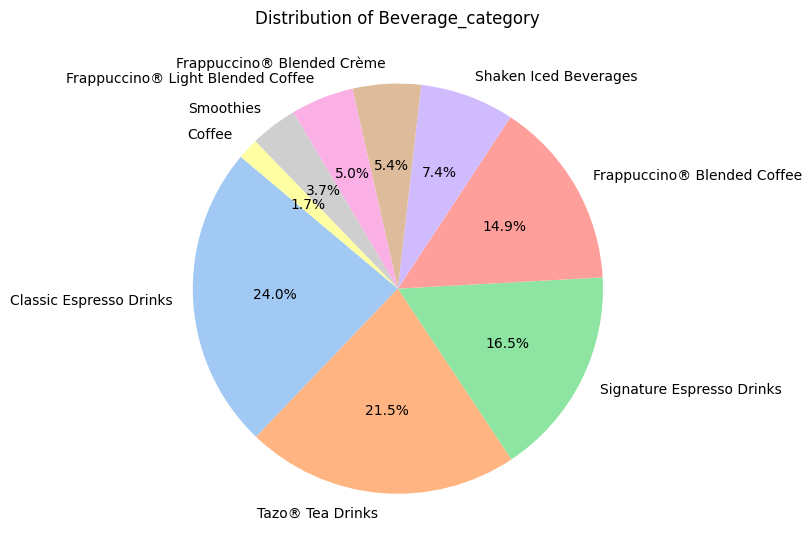

In [2]:
# We will find a suitable categorical column to visualize.
# If 'Beverage_category' is in the dataset, we will use it as our target/class.
target_col = 'Beverage_category' if 'Beverage_category' in df.columns else df.select_dtypes(include=['object']).columns[0]

# Draw a Pie Chart of the target distribution
plt.figure(figsize=(8, 8))
class_counts = df[target_col].value_counts()
plt.pie(class_counts, labels=class_counts.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('pastel'))
plt.title(f'Distribution of {target_col}')
plt.tight_layout()
plt.show()

### 2. Data Splitting and Preprocessing
We will encode categorical variables and split the data into training and test sets.

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Prepare data for modeling
df_model = df.copy()

# Encode categorical columns
label_encoders = {}
for col in df_model.select_dtypes(include=['object']).columns:
    le = LabelEncoder()
    df_model[col] = le.fit_transform(df_model[col].astype(str))
    label_encoders[col] = le

# Define Features (X) and Target (y)
# We use the designated target column determined in the EDA step
y = df_model[target_col]
X = df_model.drop(columns=[target_col])

# Split the dataset into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y if y.nunique() > 1 else None)

### 3. Decision Tree Modeling & Evaluation
Now, we train a Decision Tree Classifier and display the accuracy score and classification report.

In [4]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

# Initialize and train Decision Tree Classifier
clf = DecisionTreeClassifier(random_state=42, max_depth=5)
clf.fit(X_train, y_train)

# Predict on the test set
y_pred = clf.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy Score: {accuracy:.4f}\n")

# Get target names for the classification report if applicable
target_names = [str(cls) for cls in label_encoders[target_col].classes_]
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=target_names))

Accuracy Score: 0.8980

Classification Report:
                                   precision    recall  f1-score   support

          Classic Espresso Drinks       1.00      1.00      1.00        12
                           Coffee       1.00      1.00      1.00         1
      Frappuccino® Blended Coffee       0.88      1.00      0.93         7
       Frappuccino® Blended Crème       1.00      1.00      1.00         3
Frappuccino® Light Blended Coffee       0.20      0.50      0.29         2
            Shaken Iced Beverages       1.00      0.50      0.67         4
        Signature Espresso Drinks       1.00      0.75      0.86         8
                        Smoothies       1.00      1.00      1.00         2
                 Tazo® Tea Drinks       1.00      1.00      1.00        10

                         accuracy                           0.90        49
                        macro avg       0.90      0.86      0.86        49
                     weighted avg       0.95      0

### 4. Sample Predictions Comparison
Let's extract 10 random samples from the test data to compare their **Actual Category** against the **Predicted Category**.

In [5]:
# Select 10 sample indices from the test set
sample_X = X_test.head(10)
sample_y_actual = y_test.head(10)

# Generate predictions for these 10 samples
sample_y_pred = clf.predict(sample_X)

# Decode numerical classes back to original beverage category names
encoder = label_encoders[target_col]
actual_categories = encoder.inverse_transform(sample_y_actual)
predicted_categories = encoder.inverse_transform(sample_y_pred)

# Create a comparison DataFrame
comparison_df = pd.DataFrame({
    'Beverage': df.loc[sample_X.index, 'Beveria_name' if 'Beveria_name' in df.columns else 'Beverage'],
    'Actual Category': actual_categories,
    'Predicted Category': predicted_categories
})

# Highlight matches
comparison_df['Correct Prediction'] = comparison_df['Actual Category'] == comparison_df['Predicted Category']

display(comparison_df)

,Beverage,Actual Category,Predicted Category,Correct Prediction
197,Mocha (Without Whipped Cream),Frappuccino® Blended Coffee,Frappuccino® Blended Coffee,True
88,Hot Chocolate (Without Whipped Cream),Signature Espresso Drinks,Frappuccino® Light Blended Coffee,False
42,Caffè Americano,Classic Espresso Drinks,Classic Espresso Drinks,True
32,Vanilla Latte (Or Other Flavoured Latte),Classic Espresso Drinks,Classic Espresso Drinks,True
107,Tazo® Chai Tea Latte,Tazo® Tea Drinks,Tazo® Tea Drinks,True
11,Caffè Latte,Classic Espresso Drinks,Classic Espresso Drinks,True
52,Cappuccino,Classic Espresso Drinks,Classic Espresso Drinks,True
155,Iced Brewed Coffee (With Classic Syrup),Shaken Iced Beverages,Shaken Iced Beverages,True
2,Brewed Coffee,Coffee,Coffee,True
62,Caramel Macchiato,Signature Espresso Drinks,Signature Espresso Drinks,True
